# Artillería por turnos: dos jugadores

## 1. Reglas
- El jugador 1 está a la izquierda y dispara hacia la derecha. El jugador 2 está a la derecha y dispara hacia la izquierda.
- En su turno cada uno elige **retroceder 10 m, quedarse o avanzar 10 m**. Después elige ángulo y potencia y dispara.
- El jugador 1 puede estar entre 0 y 40 m; el jugador 2, entre 60 y 100 m. Así no se cruzan. Los movimientos fuera de esos límites no están permitidos.
- Gana quien haga caer el proyectil a 5 m o menos del rival. Si nadie acierta en 10 turnos totales, hay empate.
- Recompensas al final, **ganador 1, perdedor 0, empate 0.5 para ambos**.

Una acción es `(movimiento, ángulo, potencia)`. Se elige completa y se ejecuta en ese orden. El estado contiene las posiciones de los dos jugadores; cada agente guarda sus propios valores.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
movimientos = [-10, 0, 10]  
angulos = [30, 45, 60]
potencias = [15, 20, 25, 30]
acciones = [(m, a, p) for m in movimientos for a in angulos for p in potencias]
tolerancia = 5
gravedad = 9.81
max_turnos = 10

print("Acciones posibles:", len(acciones))

Acciones posibles: 36


## 2. Tablero y disparo


In [2]:
class Board:
    def __init__(self):
        self.reset()

    def reset(self, posiciones=(0, 100)):
        self.posiciones = list(posiciones)

    def valid_moves(self, jugador):
        direccion = 1 if jugador == 0 else -1
        minimo, maximo = (0, 40) if jugador == 0 else (60, 100)
        validas = []
        for i, (movimiento, angulo, potencia) in enumerate(acciones):
            nueva = self.posiciones[jugador] + direccion * movimiento
            if minimo <= nueva <= maximo:
                validas.append(i)
        return validas

    def update(self, jugador, accion):
        if accion not in self.valid_moves(jugador):
            raise ValueError("Movimiento fuera del tablero")
        movimiento, angulo, potencia = acciones[accion]
        direccion = 1 if jugador == 0 else -1
        self.posiciones[jugador] += direccion * movimiento
        origen = self.posiciones[jugador]
        objetivo = self.posiciones[1 - jugador]
        alcance = potencia ** 2 * np.sin(2 * np.radians(angulo)) / gravedad
        impacto = origen + direccion * alcance
        acierto = abs(impacto - objetivo) <= tolerancia
        return origen, objetivo, impacto, acierto

## 3. Agente: explorar, jugar y aprender
Como en el agente del tres en raya, cada jugador tiene su propia tabla y guarda las decisiones de la partida.

La clave de la tabla es `(posiciones, acción)`: sirve para distinguir un disparo realizado desde lugares diferentes.
La única regla de actualización del aprendizaje es la vista en los cuadernillos:


Al terminar, recorremos las decisiones en orden inverso. Después de actualizar una decisión, su valor actualizado se pasa a la anterior. Así asociamos las decisiones al resultado de la partida.

In [3]:
class Agent:
    def __init__(self, alpha=0.5, prob_exp=0.3):
        self.value_function = {}
        self.alpha = alpha
        self.prob_exp = prob_exp
        self.positions = []

    def reset(self):
        self.positions = []

    def move(self, board, jugador, explore=True):
        validas = board.valid_moves(jugador)
        estado = tuple(board.posiciones)
        if explore and np.random.uniform(0, 1) < self.prob_exp:
            return int(np.random.choice(validas))
        valores = [self.value_function.get((estado, a), 0) for a in validas]
        mejores = [a for a, v in zip(validas, valores) if v == max(valores)]
        return int(np.random.choice(mejores))

    def update(self, board, accion):
        self.positions.append((tuple(board.posiciones), accion))

    def reward(self, recompensa):
        for clave in reversed(self.positions):
            valor = self.value_function.get(clave, 0)
            valor += self.alpha * (recompensa - valor)
            self.value_function[clave] = valor
            recompensa = valor

## 4. Juego: alternar los turnos
`Game` reúne al tablero y a los dos agentes, como en tres en raya. Guarda la decisión **antes** de mover y disparar. Al acertar, termina inmediatamente y reparte las recompensas.

Separamos `explore` de `aprender`: podemos ver una partida exploratoria sin modificar lo que ya aprendieron.

In [4]:
class Game:
    def __init__(self, player1, player2):
        self.players = [player1, player2]
        self.board = Board()

    def play(self, inicio=0, posiciones=(0, 100), explore=True, aprender=True):
        self.board.reset(posiciones)
        for player in self.players:
            player.reset()
        historial = []
        ganador = None

        for turno in range(max_turnos):
            jugador = (inicio + turno) % 2
            player = self.players[jugador]
            accion = player.move(self.board, jugador, explore)
            player.update(self.board, accion)
            origen, objetivo, impacto, acierto = self.board.update(jugador, accion)
            historial.append((jugador, accion, origen, objetivo, impacto, acierto))
            if acierto:
                ganador = jugador
                break

        if aprender:
            for i, player in enumerate(self.players):
                recompensa = 0.5 if ganador is None else int(i == ganador)
                player.reward(recompensa)
        return ganador, historial

## 5. Entrenar jugando entre ellos
Los dos agentes aprenden durante 20.000 partidas. Alternamos quién empieza y variamos las posiciones iniciales dentro de sus zonas para practicar distintas situaciones. Cada partida reinicia el historial, pero conserva los valores aprendidos.

In [5]:
np.random.seed(42)
agent1 = Agent()
agent2 = Agent()
game = Game(agent1, agent2)
partidas = 20000
resultados = []

for partida in range(partidas):
    posiciones = (int(np.random.choice([0, 10, 20, 30, 40])),
                  int(np.random.choice([60, 70, 80, 90, 100])))
    ganador, _ = game.play(inicio=partida % 2, posiciones=posiciones)
    resultados.append(2 if ganador is None else ganador)

print("Entrenamiento terminado")
print("Victorias del jugador 1:", resultados.count(0))
print("Victorias del jugador 2:", resultados.count(1))
print("Empates:", resultados.count(2))
print("Decisiones guardadas:", len(agent1.value_function), "y", len(agent2.value_function))

Entrenamiento terminado
Victorias del jugador 1: 9949
Victorias del jugador 2: 10025
Empates: 26
Decisiones guardadas: 773 y 774


## 6. Ver una partida
Esta celda muestra cada movimiento y el disparo que le sigue. Las gráficas están separadas por turno para que se vea dónde estaba el rival en ese momento.

Puedes cambiar `inicio` a 1 para que empiece el jugador 2. `explore=False` hace que ambos aprovechen sus valores aprendidos. Con `explore=True` también prueban acciones. Una partida puede terminar en el primer disparo: quien empieza tiene una ventaja en este escenario.

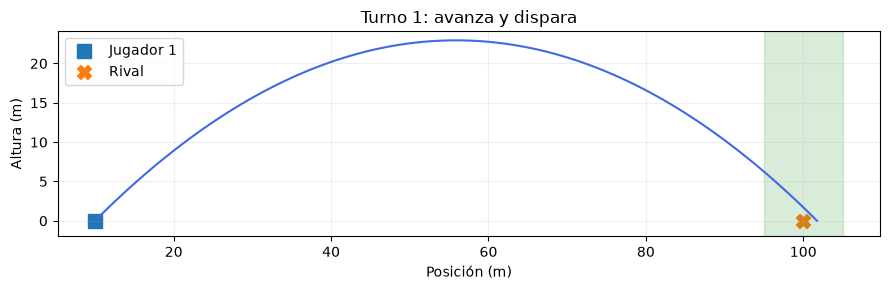

Turno 1: jugador 1 avanza; posición 10 m.
  Dispara a 45° con potencia 30: cae en 101.7 m. Rival en 100 m.
¡Gana el jugador 1!


In [6]:
np.random.seed(9)
ganador, historial = game.play(inicio=0, posiciones=(0, 100), explore=False, aprender=False)
fig, ejes = plt.subplots(len(historial), 1, figsize=(9, 3 * len(historial)), squeeze=False)

for turno, (jugador, accion, origen, objetivo, impacto, acierto) in enumerate(historial):
    movimiento, angulo, potencia = acciones[accion]
    texto_movimiento = {-10: "retrocede", 0: "se queda", 10: "avanza"}[movimiento]
    print(f"Turno {turno + 1}: jugador {jugador + 1} {texto_movimiento}; posición {origen} m.")
    print(f"  Dispara a {angulo}° con potencia {potencia}: cae en {impacto:.1f} m. Rival en {objetivo} m.")
    direccion = 1 if jugador == 0 else -1
    theta = np.radians(angulo)
    tiempo = np.linspace(0, 2 * potencia * np.sin(theta) / gravedad, 100)
    x = origen + direccion * potencia * np.cos(theta) * tiempo
    y = potencia * np.sin(theta) * tiempo - 0.5 * gravedad * tiempo ** 2
    eje = ejes[turno, 0]
    eje.plot(x, y, color="royalblue" if jugador == 0 else "darkorange")
    eje.scatter([origen], [0], s=100, marker="s", label=f"Jugador {jugador + 1}")
    eje.scatter([objetivo], [0], s=100, marker="X", label="Rival")
    eje.axvspan(objetivo - tolerancia, objetivo + tolerancia, color="green", alpha=0.15)
    eje.set(title=f"Turno {turno + 1}: {texto_movimiento} y dispara", xlabel="Posición (m)", ylabel="Altura (m)", ylim=(-2, None))
    eje.legend()
    eje.grid(alpha=0.2)

plt.tight_layout()
plt.show()
print("Empate" if ganador is None else f"¡Gana el jugador {ganador + 1}!")

## 7. Comprobar contra un jugador aleatorio
Probamos cada agente entrenado contra un rival que siempre explora. En 500 partidas por agente alternamos quién empieza y usamos posiciones de las practicadas. No actualizamos los valores en estas pruebas.

Estos resultados describen este escenario y este rival, no una garantía de ganar siempre. El turno inicial influye mucho.

In [7]:
np.random.seed(123)
for numero, agente in enumerate([agent1, agent2]):
    rivales = [agente, Agent(prob_exp=1)] if numero == 0 else [Agent(prob_exp=1), agente]
    prueba = Game(*rivales)
    victorias = derrotas = empates = 0
    victorias_inicio = victorias_segundo = 0
    for partida in range(500):
        posiciones = (int(np.random.choice([0, 10, 20, 30, 40])),
                      int(np.random.choice([60, 70, 80, 90, 100])))
        # El entrenado explota; el rival mantiene exploración del 100 %.
        prob_anterior = agente.prob_exp
        agente.prob_exp = 0
        ganador, _ = prueba.play(inicio=partida % 2, posiciones=posiciones, aprender=False)
        agente.prob_exp = prob_anterior
        if ganador is None:
            empates += 1
        elif ganador == numero:
            victorias += 1
            if partida % 2 == numero:
                victorias_inicio += 1
            else:
                victorias_segundo += 1
        else:
            derrotas += 1
    print(f"Jugador {numero + 1}: {victorias} victorias, {derrotas} derrotas, {empates} empates.")
    print(f"  Gana empezando: {victorias_inicio}/250; jugando segundo: {victorias_segundo}/250.")

Jugador 1: 476 victorias, 24 derrotas, 0 empates.
  Gana empezando: 250/250; jugando segundo: 226/250.
Jugador 2: 469 victorias, 31 derrotas, 0 empates.
  Gana empezando: 250/250; jugando segundo: 219/250.
